In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("C:/Users/ELCOT/Downloads/hotel_bookings.csv/hotel_bookings.csv")

In [4]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [5]:
df.shape

(119390, 32)

In [6]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')

In [7]:
df.dtypes

hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent                             

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [9]:
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [10]:
df['children'] = df['children'].fillna(df['children'].median())

In [11]:
df['country'] = df['country'].fillna('Unknown')

In [12]:
categorical_cols = [
    'hotel',
    'meal',
    'market_segment',
    'distribution_channel',
    'reserved_room_type',
    'deposit_type',
    'customer_type',
    'reservation_status'
]

print(categorical_cols)

['hotel', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type', 'reservation_status']


In [13]:
df[categorical_cols].head()

,hotel,meal,market_segment,distribution_channel,reserved_room_type,deposit_type,customer_type,reservation_status
0,Resort Hotel,BB,Direct,Direct,C,No Deposit,Transient,Check-Out
1,Resort Hotel,BB,Direct,Direct,C,No Deposit,Transient,Check-Out
2,Resort Hotel,BB,Direct,Direct,A,No Deposit,Transient,Check-Out
3,Resort Hotel,BB,Corporate,Corporate,A,No Deposit,Transient,Check-Out
4,Resort Hotel,BB,Online TA,TA/TO,A,No Deposit,Transient,Check-Out


In [14]:
df_encoded = pd.get_dummies(
    df,
    columns=categorical_cols,
    dtype=int
)

df_encoded.head()

,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,...,deposit_type_No Deposit,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Contract,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,reservation_status_Canceled,reservation_status_Check-Out,reservation_status_No-Show
0,0,342,2015,July,27,1,0,0,2,0.0,...,1,0,0,0,0,1,0,0,1,0
1,0,737,2015,July,27,1,0,0,2,0.0,...,1,0,0,0,0,1,0,0,1,0
2,0,7,2015,July,27,1,0,1,1,0.0,...,1,0,0,0,0,1,0,0,1,0
3,0,13,2015,July,27,1,0,1,1,0.0,...,1,0,0,0,0,1,0,0,1,0
4,0,14,2015,July,27,1,0,2,2,0.0,...,1,0,0,0,0,1,0,0,1,0


In [15]:
frequency = df['hotel'].value_counts()

print(frequency)

hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64


In [16]:
percentage = df['hotel'].value_counts(normalize=True) * 100

print(percentage)

hotel
City Hotel      66.446101
Resort Hotel    33.553899
Name: proportion, dtype: float64


In [17]:
most_common = df['hotel'].value_counts().idxmax()

print("Most Common Hotel:", most_common)

Most Common Hotel: City Hotel


In [18]:
for col in categorical_cols:

    print("\nColumn:", col)

    print("\nFrequency Distribution:")
    print(df[col].value_counts())

    print("\nPercentage Distribution:")
    print(df[col].value_counts(normalize=True) * 100)

    print("\nMost Common Category:")
    print(df[col].value_counts().idxmax())


Column: hotel

Frequency Distribution:
hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64

Percentage Distribution:
hotel
City Hotel      66.446101
Resort Hotel    33.553899
Name: proportion, dtype: float64

Most Common Category:
City Hotel

Column: meal

Frequency Distribution:
meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64

Percentage Distribution:
meal
BB           77.318033
HB           12.114080
SC            8.920345
Undefined     0.979144
FB            0.668398
Name: proportion, dtype: float64

Most Common Category:
BB

Column: market_segment

Frequency Distribution:
market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64

Percentage Distribution:
market_segment
Online TA        47.304632
Offline TA/TO    20.2

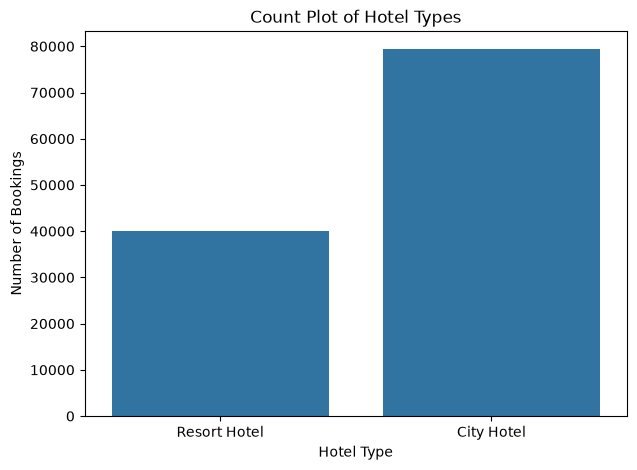

In [19]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x='hotel')

plt.title("Count Plot of Hotel Types")
plt.xlabel("Hotel Type")
plt.ylabel("Number of Bookings")

plt.show()

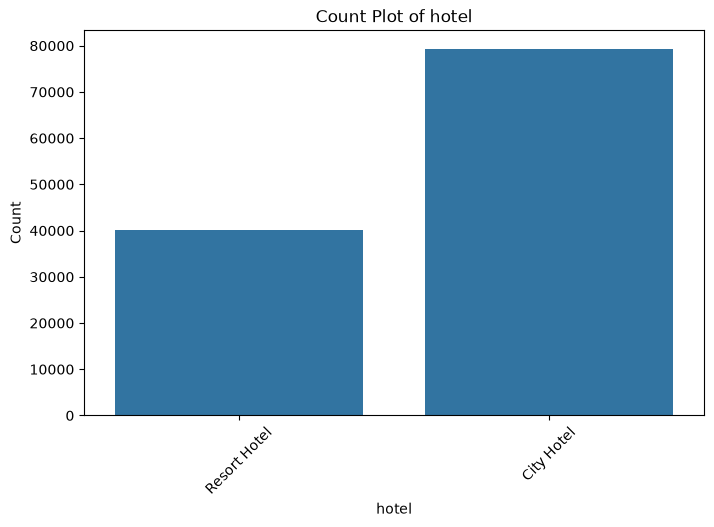

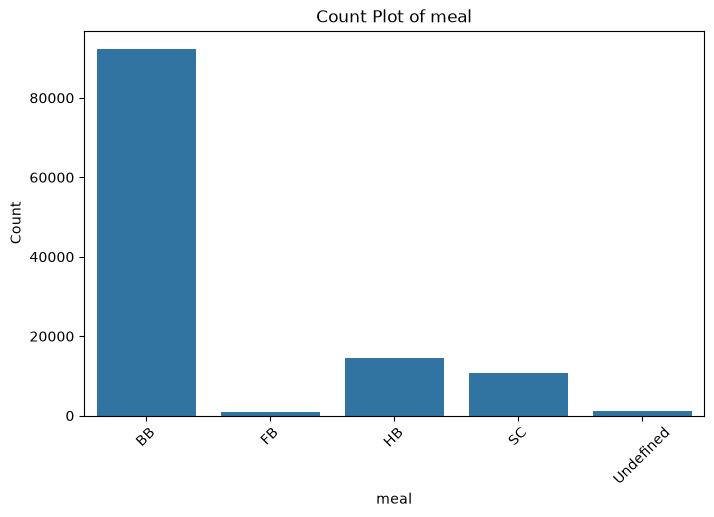

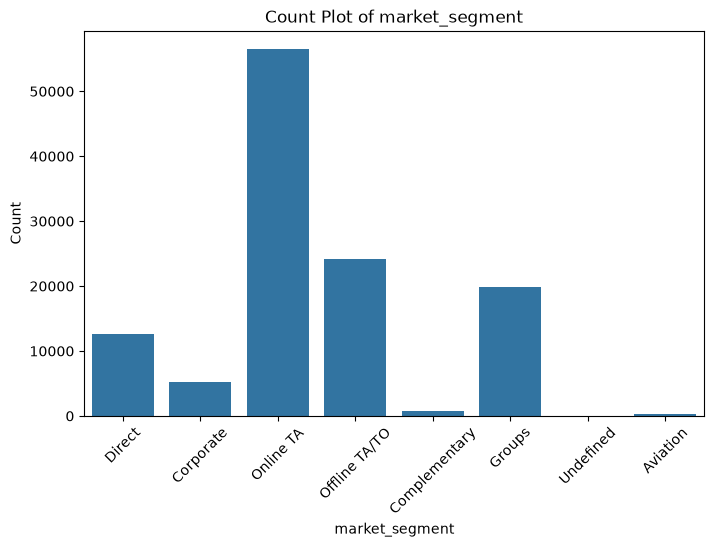

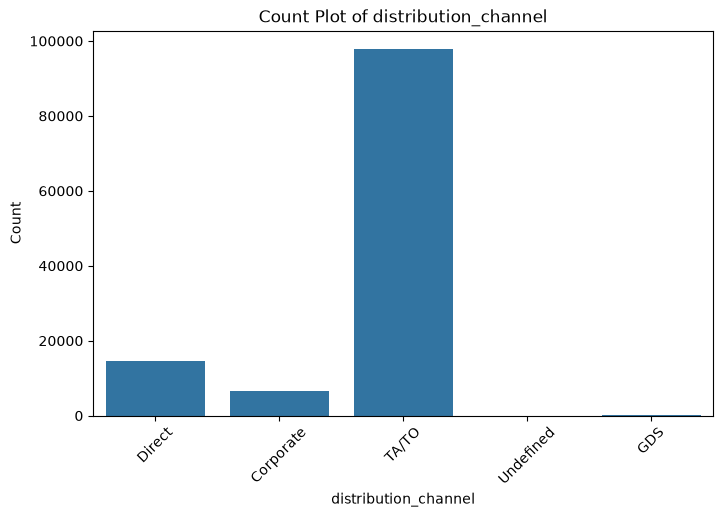

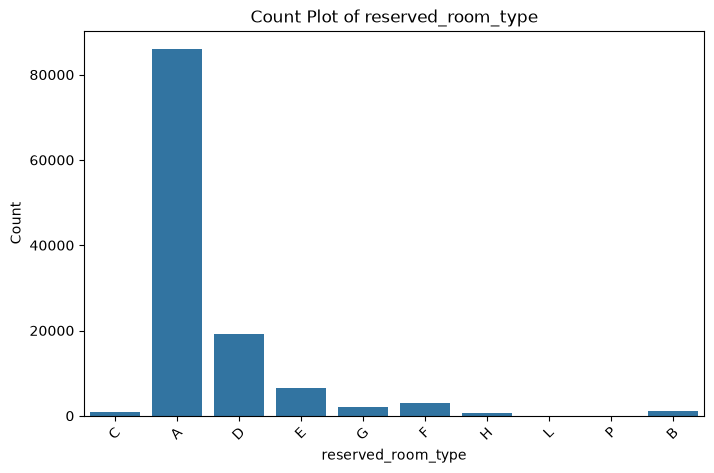

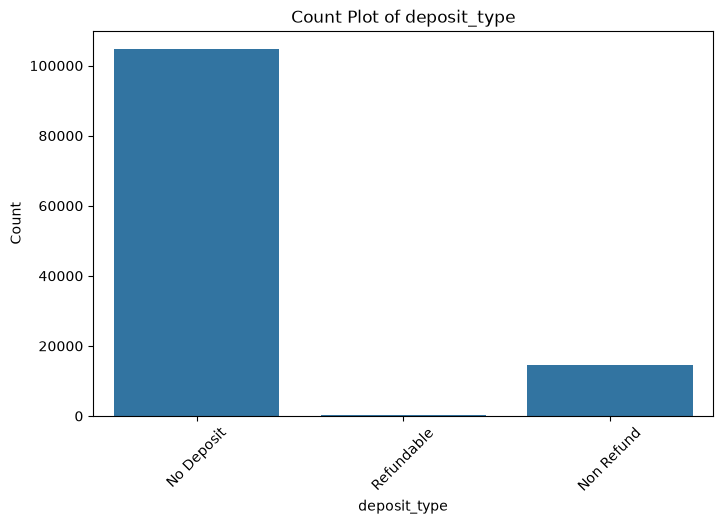

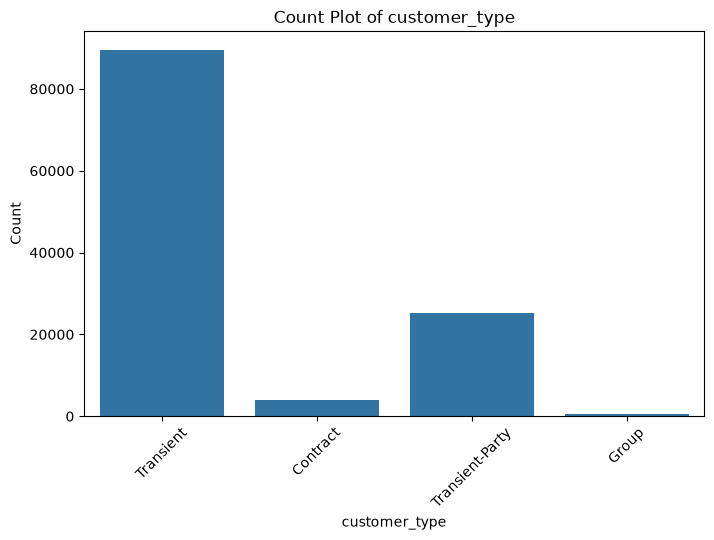

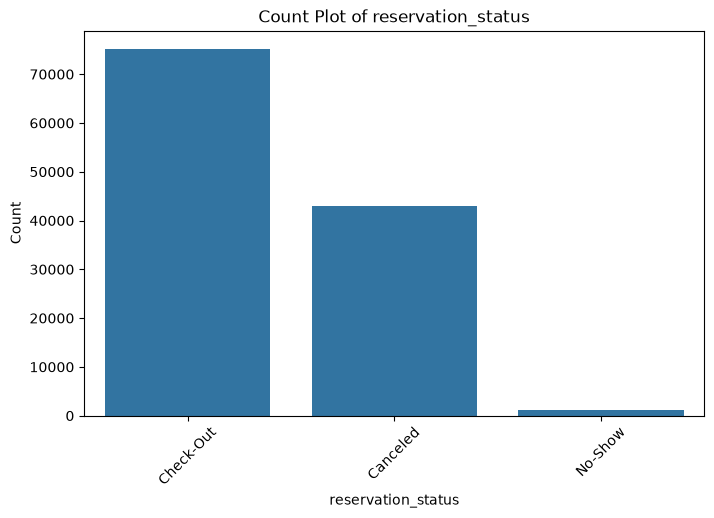

In [20]:
for col in categorical_cols:

    plt.figure(figsize=(8,5))

    sns.countplot(data=df, x=col)

    plt.title("Count Plot of " + col)
    plt.xlabel(col)
    plt.ylabel("Count")

    plt.xticks(rotation=45)

    plt.show()

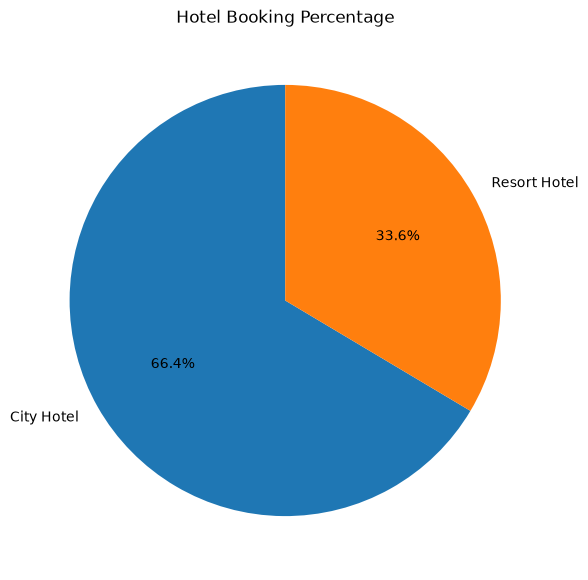

In [21]:
hotel_counts = df['hotel'].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    hotel_counts,
    labels=hotel_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Hotel Booking Percentage")

plt.show()

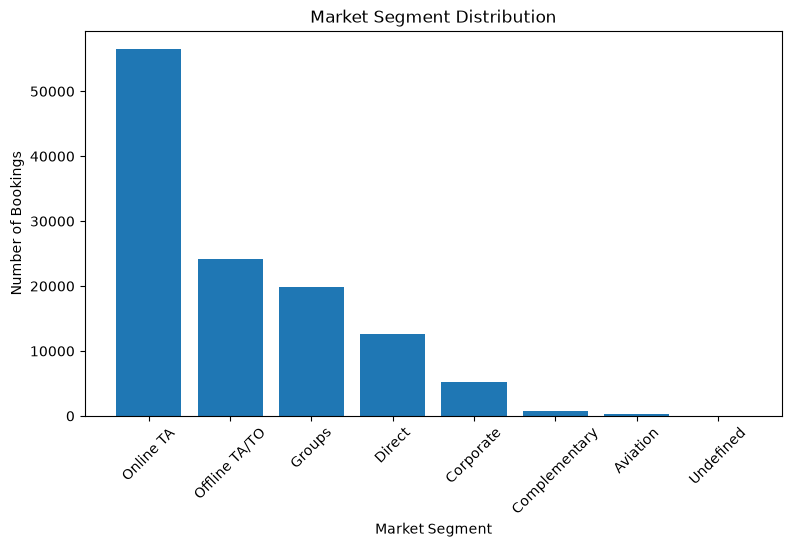

In [22]:
market_counts = df['market_segment'].value_counts()

plt.figure(figsize=(9,5))

plt.bar(market_counts.index, market_counts.values)

plt.title("Market Segment Distribution")
plt.xlabel("Market Segment")
plt.ylabel("Number of Bookings")

plt.xticks(rotation=45)

plt.show()

In [23]:
comparison = pd.crosstab(
    df['hotel'],
    df['market_segment']
)

print(comparison)

market_segment  Aviation  Complementary  Corporate  Direct  Groups  \
hotel                                                                
City Hotel           237            542       2986    6093   13975   
Resort Hotel           0            201       2309    6513    5836   

market_segment  Offline TA/TO  Online TA  Undefined  
hotel                                                
City Hotel              16747      38748          2  
Resort Hotel             7472      17729          0  


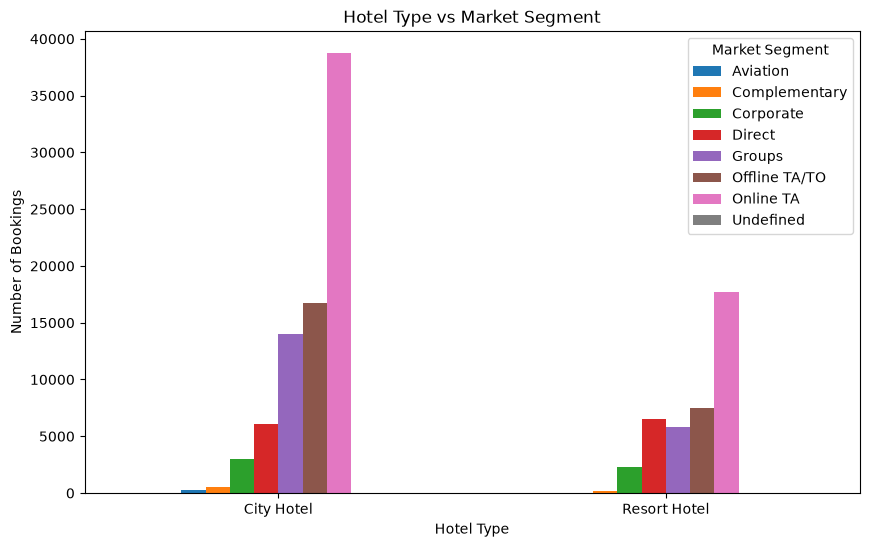

In [24]:
comparison.plot(
    kind='bar',
    figsize=(10,6)
)

plt.title("Hotel Type vs Market Segment")
plt.xlabel("Hotel Type")
plt.ylabel("Number of Bookings")

plt.xticks(rotation=0)

plt.legend(title="Market Segment")

plt.show()